# 03 Convergence

This notebook measures how fast the random surfer's distribution approaches π and
compares it with the idea that after k steps, the total variation distance is at most α^k times the starting distance.

In [13]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.load import load_graph
from src.chain import build_chain, distances

A, node_ids, info = load_graph()
PT, dangling = build_chain(A)
n = A.shape[0]

ALPHAS = [0.50, 0.70, 0.85, 0.95, 0.99]
FLOOR = 1e-10
pis = {alpha: np.load(f"../data/pi_alpha_{alpha:.2f}.npy") for alpha in ALPHAS}

## Starting distributions

The experiment uses three starting points: the uniform distribution (standard), all mass on the top-ranked page; and all mass on one page chosen at random with a fixed seed.

In [14]:
rng = np.random.default_rng(0)
top_page = int(np.argmax(pis[0.85]))
random_page = int(rng.integers(n))


def point_mass(i):
    x = np.zeros(n)
    x[i] = 1.0
    return x


starts = {
    "uniform": np.full(n, 1.0 / n),
    "top page": point_mass(top_page),
    "random page": point_mass(random_page),
}

## Measuring the distance

For each α and each start, the chain is run and the TV distance to π is recorded
at every step down to 10⁻¹⁰.

In [15]:
records = []
for alpha in ALPHAS:
    for name, x0 in starts.items():
        d = distances(x0, pis[alpha], PT, dangling, alpha, floor=FLOOR)
        k = np.arange(len(d))
        bound = alpha**k * d[0]
        records.append(pd.DataFrame({
            "alpha": alpha, "start": name, "k": k,
            "tv": d, "bound": bound, "ratio": d / bound,
        }))

results = pd.concat(records, ignore_index=True)
results = results[results["tv"] >= FLOOR]
results.to_csv("../data/convergence.csv", index=False)
results.groupby(["alpha", "start"])["k"].max().unstack()

start,random page,top page,uniform
alpha,,,
0.50,32,33,26
0.70,63,64,51
0.85,138,140,114
0.95,435,445,360
0.99,2214,2271,1779


A start at distance 1 from π needs ln(10⁻¹⁰)/ln α steps under the bound: 33, 65,
142, 449 and 2,291 for the five values of α. The runs from a single page finish
within 1% to 4% of those counts. The uniform start finishes about 20% sooner.

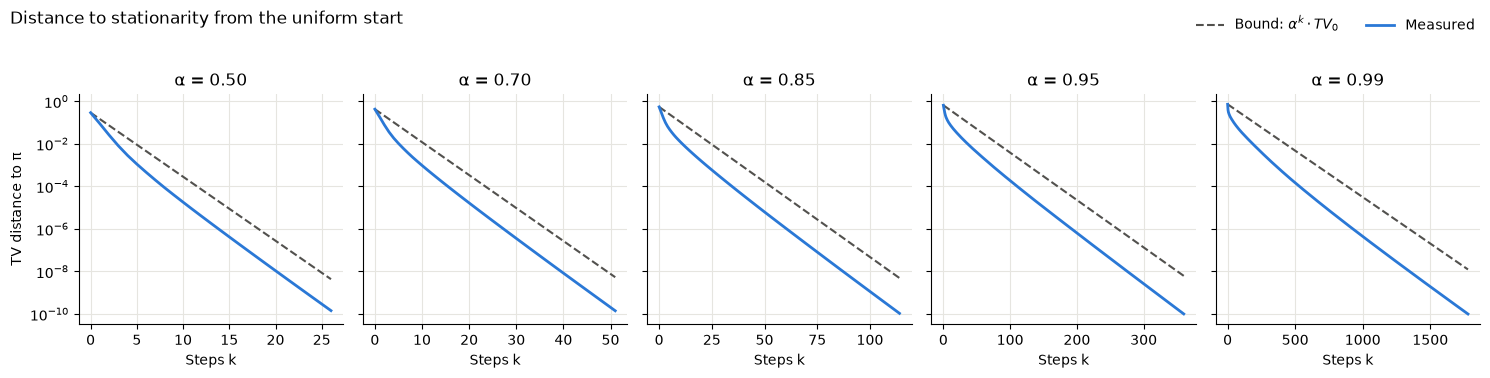

In [16]:
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"

fig, axes = plt.subplots(1, len(ALPHAS), figsize=(15, 3.8), sharey=True)
for ax, alpha in zip(axes, ALPHAS):
    g = results[(results["alpha"] == alpha) & (results["start"] == "uniform")]
    ax.semilogy(g["k"], g["bound"], "--", color=GREY, linewidth=1.5, label=r"Bound: $\alpha^k \cdot TV_0$")
    ax.semilogy(g["k"], g["tv"], color=BLUE, linewidth=2, label="Measured")
    ax.set_title(f"α = {alpha:.2f}")
    ax.set_xlabel("Steps k")
    ax.grid(True, which="major", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("TV distance to π")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.995, 1.0), ncol=2, frameon=False)
fig.suptitle("Distance to stationarity from the uniform start", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("../figures/01_convergence.png", dpi=150)

After a steeper initial drop, the measured line runs nearly parallel to the bound
and drifts away from it, meaning the chain converges at close to rate α with a headstart.

## The ratio

Dividing the measured distance by the bound gives a ratio r_k. We want to assert that it can never exceed 1 and can never rise. 

In [17]:
for (alpha, start), g in results.groupby(["alpha", "start"]):
    r = g["ratio"].to_numpy()
    assert r.max() <= 1 + 1e-6, (alpha, start)
    assert np.diff(r).max() <= 1e-6, (alpha, start)
print("ratio checks passed")

ratio checks passed


Both properties hold in all 15 runs.

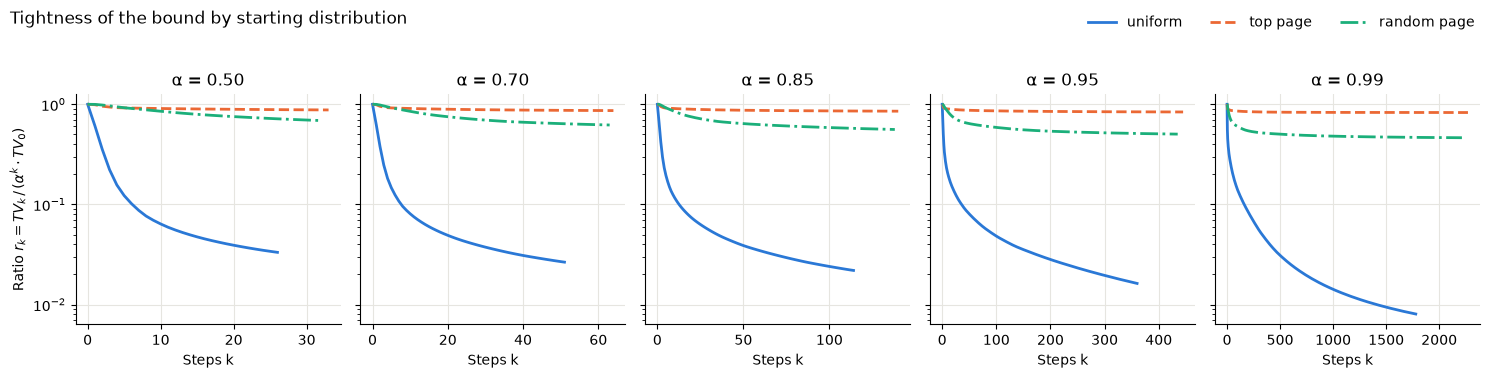

In [18]:
styles = {"uniform": (BLUE, "-"), "top page": (ORANGE, "--"), "random page": (AQUA, "-.")}

fig, axes = plt.subplots(1, len(ALPHAS), figsize=(15, 3.8), sharey=True)
for ax, alpha in zip(axes, ALPHAS):
    for name, (color, linestyle) in styles.items():
        g = results[(results["alpha"] == alpha) & (results["start"] == name)]
        ax.semilogy(g["k"], g["ratio"], linestyle, color=color, linewidth=2, label=name)
    ax.set_title(f"α = {alpha:.2f}")
    ax.set_xlabel("Steps k")
    ax.grid(True, which="major", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(r"Ratio $r_k = TV_k \,/\, (\alpha^k \cdot TV_0)$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.995, 1.0), ncol=3, frameon=False)
fig.suptitle("Tightness of the bound by starting distribution", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("../figures/02_tightness_ratio.png", dpi=150)

## The rate

On a log scale, convergence at rate α is a straight line with slope ln α. So, we compare the second half of each runs slope with ln α.

In [19]:
def tail_slope(g):
    tail = g[g["k"] >= g["k"].max() / 2]
    return np.polyfit(tail["k"], np.log(tail["tv"]), 1)[0]


rows = []
for (alpha, start), g in results.groupby(["alpha", "start"]):
    rows.append({
        "alpha": alpha, "start": start, "ln alpha": np.log(alpha),
        "fitted slope": tail_slope(g), "final ratio": g["ratio"].iloc[-1],
    })
rates = pd.DataFrame(rows)
rates["slope / ln alpha"] = rates["fitted slope"] / rates["ln alpha"]
rates.round(4)

,alpha,start,ln alpha,fitted slope,final ratio,slope / ln alpha
0,0.50,random page,-0.6931,-0.7013,0.6877,1.0118
1,0.50,top page,-0.6931,-0.6944,0.8781,1.0017
2,0.50,uniform,-0.6931,-0.7277,0.0332,1.0498
3,0.70,random page,-0.3567,-0.3598,0.6211,1.0087
4,0.70,top page,-0.3567,-0.3572,0.8651,1.0015
5,0.70,uniform,-0.3567,-0.3740,0.0265,1.0487
6,0.85,random page,-0.1625,-0.1638,0.5602,1.0081
7,0.85,top page,-0.1625,-0.1627,0.8533,1.0012
8,0.85,uniform,-0.1625,-0.1709,0.0219,1.0519
9,0.95,random page,-0.0513,-0.0516,0.5036,1.0051


The ratio depends strongly on where the chain starts.

- From the top-ranked page it levels off between 0.83 and 0.88, and the fitted
  slope matches ln α to within 0.2%. The bound is nearly attained.
- From a random page it declines slowly and flattens. In the longest run, at
  α = 0.99, it is nearly level just under 0.5 from about 500 steps onward, and the
  fitted slope is within 1.2% of ln α at every α.
- From the uniform start it ends between 0.008 and 0.033, and the slope is 5% to
  8% steeper than ln α. The ratio is still falling when the measurement reaches
  10⁻¹⁰, so these data do not show whether it levels off.

For a start concentrated on one page, the worst-case bound is within a factor of
about two of what happens. For the uniform start, the chain is 30 to 125 times
closer to π than the bound guarantees.

## Steps to a fixed accuracy

How many steps does it take to get within 10⁻⁶ of π from the uniform start?

In [20]:
TARGET = 1e-6
rows = []
for alpha in ALPHAS:
    g = results[(results["alpha"] == alpha) & (results["start"] == "uniform")]
    measured = int(g.loc[g["tv"] < TARGET, "k"].min())
    predicted = int(np.ceil(np.log(TARGET / g["tv"].iloc[0]) / np.log(alpha)))
    rows.append({"alpha": alpha, "steps measured": measured, "steps from bound": predicted})
pd.DataFrame(rows)

,alpha,steps measured,steps from bound
0,0.50,14,19
1,0.70,28,37
2,0.85,61,82
3,0.95,193,262
4,0.99,928,1343


From the uniform start, the chain is within 10⁻⁶ of π after 61 steps at α = 0.85,
where the bound guarantees it by 82. Across the five values of α the measured
count is 69% to 76% of the bound's. The bound overestimates by about a third.

## Summary

The α^k bound is valid in every run, but its tightness depends on its start.